#  Détection d'Intrusion réseau — CSE-CIC-IDS2018 (Classification Multiclasse)
### Comparaison de performance entre XGBoost, SVM et Random Forest — Classification à 8 classes

**Master 1 — Cybersécurité Intelligente et Technologies Émergentes**
**Module :** Machine Learning
**Projet :** Comparaison d'algorithmes de Machine Learning pour la détection d'intrusion (IDS) sur une base de données cyber

**Source du dataset :** [Kaggle — solarmainframe/ids-intrusion-csv](https://www.kaggle.com/datasets/solarmainframe/ids-intrusion-csv)
**Source originale :** https://www.unb.ca/cic/datasets/ids-2018.html

Fichiers utilisés : `03-02-2018.csv`, `03-01-2018.csv`, `02-23-2018.csv`, `02-14-2018.csv`


---
##  1- Introduction

### 1.1 - Contexte et problématique

Les systèmes de détection d'intrusion (*Intrusion Detection Systems*, IDS) sont un élément central de toute architecture de cybersécurité moderne. Leur rôle est d'analyser le trafic réseau afin de distinguer une activité **légitime (Benign)** d'une activité **malveillante**, et idéalement d'identifier précisément le **type d'attaque** en cours (reconnaissance, brute force, injection, infiltration, etc.).

Une approche purement binaire (Bénin / Malveillant) permet de détecter qu'une attaque a lieu, mais ne permet pas à l'analyste de sécurité de prioriser sa réponse : une attaque par force brute SSH et une injection SQL n'appellent pas la même réaction opérationnelle. C'est pourquoi ce projet adopte une approche **multiclasse à 8 classes**, qui conserve la nature exacte de chaque type de trafic.

### 1.2 - Objectifs du projet

1. Construire un pipeline complet de Machine Learning (chargement, nettoyage, exploration, sélection de features, entraînement, évaluation) sur le dataset **CSE-CIC-IDS2018**, l'un des jeux de données de référence en détection d'intrusion réseau.
2. Entraîner et comparer **trois algorithmes de classification supervisée** aux philosophies différentes :
   - **Random Forest** — méthode d'ensemble par agrégation (*bagging*) d'arbres de décision ;
   - **XGBoost** — méthode d'ensemble par boosting de gradient ;
   - **SVM (Support Vector Machine)** — méthode à séparateurs à vaste marge.
3. Évaluer ces algorithmes selon plusieurs **mesures de performance** (Accuracy, Precision, Recall, F1-score, ROC-AUC, temps d'entraînement) afin de déterminer lequel est le plus adapté à un cas d'usage IDS réel, où le **déséquilibre des classes** et le **coût d'une fausse alerte/d'un faux négatif** sont des enjeux critiques.
4. Tirer des conclusions argumentées sur les forces et limites de chaque approche.

### 1.3 - Présentation du dataset

Le dataset **CSE-CIC-IDS2018**, produit par le *Canadian Institute for Cybersecurity* (CIC) en collaboration avec la *Communications Security Establishment* (CSE), simule un trafic réseau réaliste (utilisateurs légitimes + scénarios d'attaque) capturé sur plusieurs jours. Chaque ligne représente un **flux réseau** (*network flow*) décrit par près de 80 caractéristiques statistiques (durée, nombre de paquets, taille des paquets, drapeaux TCP, fenêtres de congestion, etc.), extraites à l'aide de l'outil CICFlowMeter.

La variable cible `Label` indique la nature du flux parmi **8 classes** :
- `Benign` — trafic légitime
- `Bot` — trafic généré par un botnet
- `Brute Force -Web` — attaque par force brute sur une application web
- `Brute Force -XSS` — attaque XSS (Cross-Site Scripting)
- `FTP-BruteForce` — attaque par force brute sur le protocole FTP
- `Infilteration` — infiltration / mouvement latéral dans le réseau
- `SQL Injection` — injection SQL
- `SSH-Bruteforce` — attaque par force brute sur le protocole SSH

### 1.4 - Démarche méthodologique

Le notebook suit une démarche standard de Data Science appliquée à la cybersécurité :

| Étape | Description |
|---|---|
| 1–2 | Importation des librairies et chargement / fusion des 4 fichiers CSV |
| 3 | Analyse exploratoire des données (EDA) : structure, distribution des classes, visualisations |
| 4 | Nettoyage des données : valeurs manquantes, infinies, négatives, doublons, encodage |
| 5–6 | Séparation features/cible, puis split Train/Test (stratifié, **avant** tout traitement statistique pour éviter la fuite de données) |
| 7 | Sélection des 10 meilleures features (ANOVA F-test) |
| 8 | Standardisation des données (nécessaire pour la SVM) |
| 9 | Entraînement des 3 modèles (Random Forest, XGBoost, SVM) |
| 10 | Comparaison chiffrée et graphique des performances |
| 11 | Conclusions et recommandations |

>  **Précaution méthodologique importante :** afin d'obtenir des résultats fiables et non biaisés, le scaler (`StandardScaler`) et le sélecteur de features (`SelectKBest`) sont calculés (`fit`) **uniquement sur l'ensemble d'entraînement**, puis simplement appliqués (`transform`) sur l'ensemble de test. Cela évite toute *fuite de données* (data leakage) qui gonflerait artificiellement les scores de performance.



##  Importation des librairies

In [1]:
# Librairies nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

In [2]:
import warnings

warnings.filterwarnings('ignore')  # Pour ne pas afficher les avertissements

In [3]:
# Vérification des versions installées
import sklearn
import xgboost

print(f"pandas       : {pd.__version__}")
print(f"numpy        : {np.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"xgboost      : {xgboost.__version__}")

pandas       : 3.0.3
numpy        : 2.4.6
scikit-learn : 1.9.0
xgboost      : 3.2.0



## 2-  Chargement et fusion du dataset

In [4]:
dataset_list = [
    pd.read_csv('03-02-2018.csv'),
    pd.read_csv('03-01-2018.csv'),
    pd.read_csv('02-23-2018.csv'),
    pd.read_csv('02-14-2018.csv')
]

### 2.1 - Fusion des datasets

In [5]:
dataset = pd.concat(dataset_list, ignore_index=True, axis=0)
del dataset_list  # Pour libérer de la mémoire

---
## 3 - Aperçu général du dataset

In [6]:
dataset.head(n=5)  # Modifier n pour afficher plus de lignes

,Dst Port,Protocol,Timestamp,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,...,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,443,6,02/03/2018 08:47:38,141385,9,7,553,3773.0,202,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
1,49684,6,02/03/2018 08:47:38,281,2,1,38,0.0,38,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
2,443,6,02/03/2018 08:47:40,279824,11,15,1086,10527.0,385,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
3,443,6,02/03/2018 08:47:40,132,2,0,0,0.0,0,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign
4,443,6,02/03/2018 08:47:41,274016,9,13,1285,6141.0,517,0,...,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign


In [7]:
print(f"Le dataset contient {len(dataset)} instances")

Le dataset contient 3476850 instances


In [8]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 3476850 entries, 0 to 3476849
Data columns (total 80 columns):
 #   Column             Dtype 
---  ------             ----- 
 0   Dst Port           object
 1   Protocol           object
 2   Timestamp          str   
 3   Flow Duration      object
 4   Tot Fwd Pkts       object
 5   Tot Bwd Pkts       object
 6   TotLen Fwd Pkts    object
 7   TotLen Bwd Pkts    object
 8   Fwd Pkt Len Max    object
 9   Fwd Pkt Len Min    object
 10  Fwd Pkt Len Mean   object
 11  Fwd Pkt Len Std    object
 12  Bwd Pkt Len Max    object
 13  Bwd Pkt Len Min    object
 14  Bwd Pkt Len Mean   object
 15  Bwd Pkt Len Std    object
 16  Flow Byts/s        object
 17  Flow Pkts/s        object
 18  Flow IAT Mean      object
 19  Flow IAT Std       object
 20  Flow IAT Max       object
 21  Flow IAT Min       object
 22  Fwd IAT Tot        object
 23  Fwd IAT Mean       object
 24  Fwd IAT Std        object
 25  Fwd IAT Max        object
 26  Fwd IAT Min        object

### 3.1 - Liste des colonnes (features)

In [9]:
dataset.columns

Index(['Dst Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Tot Fwd Pkts',
       'Tot Bwd Pkts', 'TotLen Fwd Pkts', 'TotLen Bwd Pkts', 'Fwd Pkt Len Max',
       'Fwd Pkt Len Min', 'Fwd Pkt Len Mean', 'Fwd Pkt Len Std',
       'Bwd Pkt Len Max', 'Bwd Pkt Len Min', 'Bwd Pkt Len Mean',
       'Bwd Pkt Len Std', 'Flow Byts/s', 'Flow Pkts/s', 'Flow IAT Mean',
       'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Tot',
       'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min',
       'Bwd IAT Tot', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max',
       'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags',
       'Bwd URG Flags', 'Fwd Header Len', 'Bwd Header Len', 'Fwd Pkts/s',
       'Bwd Pkts/s', 'Pkt Len Min', 'Pkt Len Max', 'Pkt Len Mean',
       'Pkt Len Std', 'Pkt Len Var', 'FIN Flag Cnt', 'SYN Flag Cnt',
       'RST Flag Cnt', 'PSH Flag Cnt', 'ACK Flag Cnt', 'URG Flag Cnt',
       'CWE Flag Count', 'ECE Flag Cnt', 'Down/Up Ratio', 'Pkt Size Avg',
      

### 3.2 -  Distribution des classes
**Remarque :** on observe un fort déséquilibre de classes, ce qui pourra poser problème lors de l'entraînement des modèles.

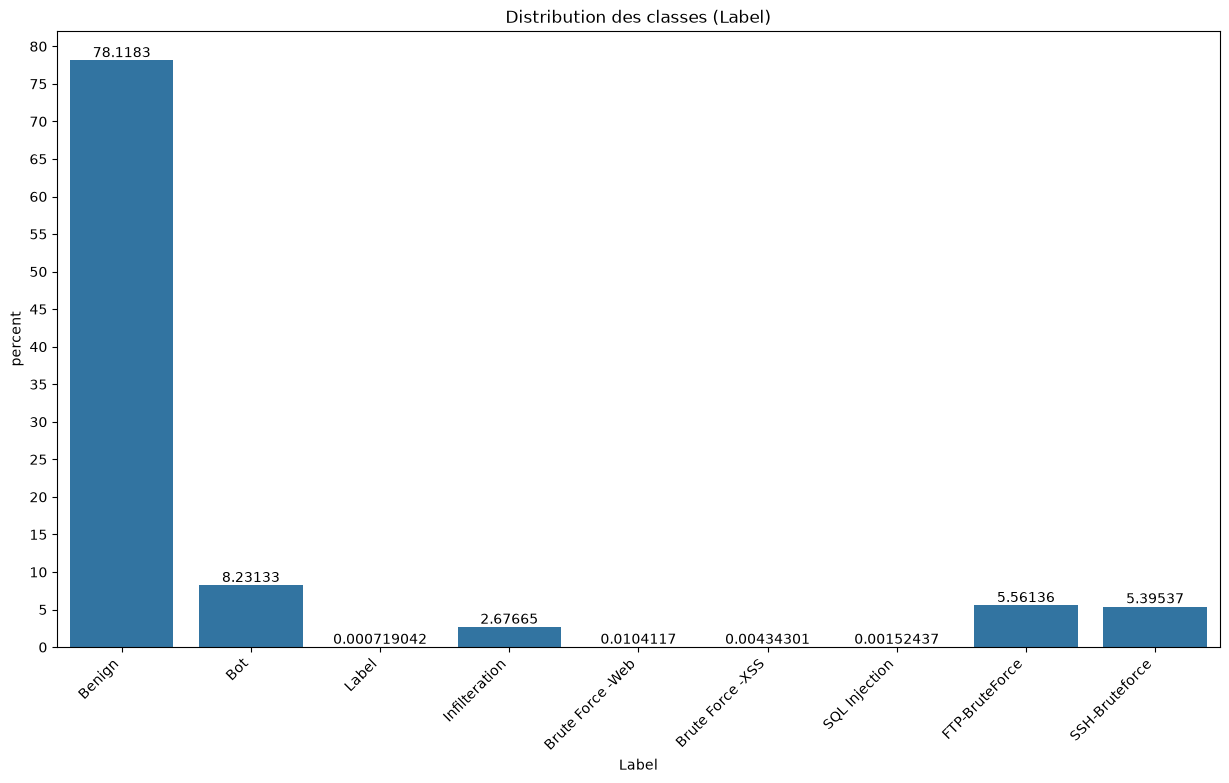

In [10]:
plt.figure(figsize=(15, 8))
plt.yticks(np.arange(0, 100, 5))
ax = sns.countplot(x="Label", data=dataset, stat='percent')

ax.bar_label(ax.containers[0], label_type='edge')
plt.title("Distribution des classes (Label)")
plt.xticks(rotation=45, ha='right')
plt.show()

**Interprétation :** la classe `Benign` représente la grande majorité des instances, tandis que des classes comme `SQL Injection` ou `Brute Force -XSS` sont extrêmement minoritaires (quelques dizaines à quelques centaines d'exemples sur plus de 3 millions de lignes). Ce déséquilibre extrême est caractéristique des données réseau réelles (les attaques sont rares par nature) et constitue l'un des défis majeurs de ce projet : un modèle qui prédirait systématiquement `Benign` afficherait déjà une accuracy très élevée sans détecter aucune attaque. C'est pourquoi l'accuracy seule ne suffit pas à juger la qualité des modèles, le `classification_report` par classe (Precision/Recall/F1 par classe) sera essentiel pour évaluer la capacité réelle de détection, en particulier sur les classes rares.


### 3.3 - Visualisation rapide : Benign vs Malicious
On regroupe temporairement toutes les attaques sous le label "Malicious" uniquement pour ces graphiques exploratoires (le dataset original `dataset` n'est pas modifié).

### 3.4 - Nettoyage préventif des lignes d'en-tête corrompues 
> **Pourquoi ici, avant même la section nettoyage officielle (étape 4) ?** Lors de la fusion de plusieurs fichiers CSV, certains fichiers Kaggle contiennent des lignes corrompues où le nom d'une colonne (ex. `"Bwd Pkts/s"`) apparaît comme **valeur** dans une cellule, au lieu d'un nombre. Si on ne les supprime pas avant l'EDA, les graphiques (`boxplot`, `violinplot`) plantent avec une erreur du type `Unable to parse string "Bwd Pkts/s"`, car ils tentent de convertir cette colonne en valeurs numériques.
> On les détecte ici via la colonne `Label` (qui contient alors un nom de colonne au lieu d'une vraie classe, ex. `'Label'` elle-même) et on les supprime tout de suite, avant de créer `dataset_eda`.

In [11]:
# On détecte les lignes corrompues en cherchant les valeurs de 'Label' qui correspondent
# à un nom de colonne existant (signe d'une ligne d'en-tête dupliquée par erreur)
noms_colonnes = set(dataset.columns)

masque_corrompu = dataset['Label'].isin(noms_colonnes)
nb_corrompues = masque_corrompu.sum()

print(f"Nombre de lignes corrompues détectées (en-têtes dupliqués) : {nb_corrompues}")

if nb_corrompues > 0:
    dataset = dataset[~masque_corrompu].reset_index(drop=True)
    print(f" Lignes corrompues supprimées. Nouvelle taille du dataset : {len(dataset):,} lignes")
else:
    print(" Aucune ligne corrompue détectée à ce stade.")

Nombre de lignes corrompues détectées (en-têtes dupliqués) : 25
 Lignes corrompues supprimées. Nouvelle taille du dataset : 3,476,825 lignes


**Interprétation :** La détection et suppression des lignes corrompues est une étape importante lors de la fusion de plusieurs fichiers CSV Kaggle. Ces lignes correspondent à des en-têtes dupliqués accidentellement insérés comme données, ce qui aurait provoqué des erreurs lors des conversions numériques et des visualisations.

In [12]:
negative_labels = ['Brute Force -Web', 'Brute Force -XSS', 'Infilteration', 'SQL Injection', 'Bot', 'SSH-Bruteforce',
                    'FTP-BruteForce']

dataset_eda = dataset.replace(negative_labels, "Malicious")

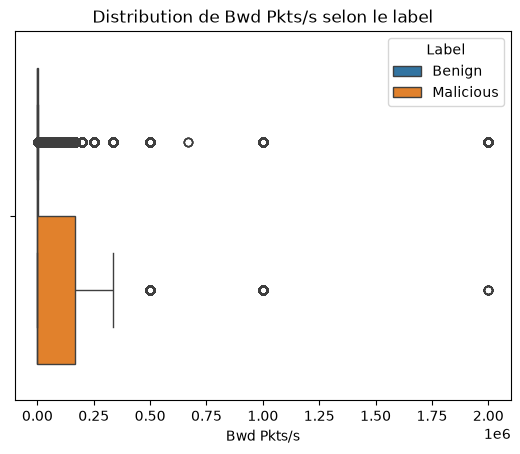

In [13]:
sns.boxplot(x="Bwd Pkts/s", hue="Label", data=dataset_eda)
plt.title("Distribution de Bwd Pkts/s selon le label")
plt.show()

**Interprétation :** Le boxplot montre que la distribution de `Bwd Pkts/s` (paquets par seconde en sens retour) diffère sensiblement entre le trafic bénin et le trafic malveillant. Les attaques génèrent souvent des valeurs extrêmes ou atypiques dans cette feature, ce qui suggère qu'elle a un pouvoir discriminant intéressant pour la classification.

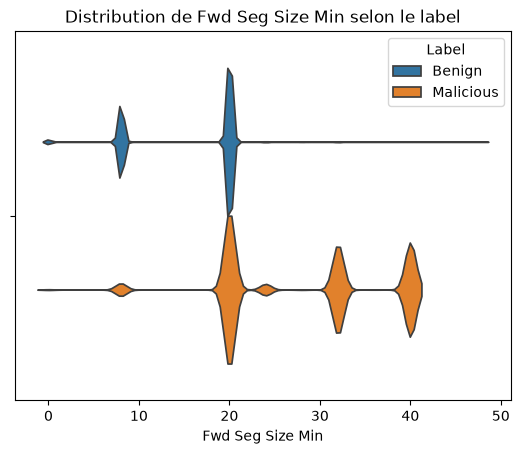

In [14]:
sns.violinplot(x="Fwd Seg Size Min", data=dataset_eda, hue="Label", inner=None)
plt.title("Distribution de Fwd Seg Size Min selon le label")
plt.show()

**Interprétation :** La feature `Fwd Seg Size Min` (taille minimale des segments en sens aller) présente une distribution très concentrée pour le trafic Benign, alors que le trafic Malicious montre plus de dispersion. Cette différence de forme indique que cette feature peut aider le modèle à distinguer les deux catégories.

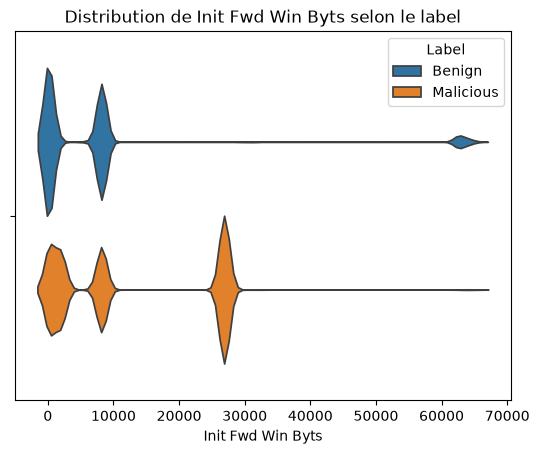

In [15]:
sns.violinplot(x="Init Fwd Win Byts", hue="Label", data=dataset_eda, inner=None)
plt.title("Distribution de Init Fwd Win Byts selon le label")
plt.show()

**Interprétation :** `Init Fwd Win Byts` (taille initiale de la fenêtre TCP en sens aller) montre des distributions clairement distinctes entre trafic bénin et malveillant. Le trafic normal tend à utiliser des fenêtres TCP plus grandes, caractéristique d'une communication légitime et fluide, tandis que certaines attaques utilisent des valeurs très faibles ou nulles.

In [16]:
del dataset_eda  # On libère la mémoire, ce DataFrame n'était que pour l'EDA

## 4 - Nettoyage des données (Data Cleaning)

### 4.1 - Suppression des colonnes non pertinentes
Les colonnes `Timestamp` et `Dst Port` n'apportent pas d'indice pertinent pour déterminer la classe.

In [17]:
dataset = dataset.drop(columns=["Timestamp", "Dst Port"])

### - 4.2  Suppression des lignes mal formées (label = 'Label') et vérification
> Cette vérification a déjà été faite en amont (étape 3.4, avant l'EDA) pour éviter que les graphiques exploratoires ne plantent. On la refait ici simplement par sécurité — la liste d'indices ci-dessous devrait normalement être **vide** à ce stade.

In [18]:
dataset['Label'].unique()  # Vérifier toutes les classes présentes ; si 'Label' y figure, exécuter la cellule suivante

<StringArray>
[          'Benign',              'Bot',    'Infilteration',
 'Brute Force -Web', 'Brute Force -XSS',    'SQL Injection',
   'FTP-BruteForce',   'SSH-Bruteforce']
Length: 8, dtype: str

In [19]:
value = 'Label'

indices_with_value = dataset.index[dataset['Label'] == value]  # Localiser les lignes avec la classe 'Label'
indices_with_value

RangeIndex(start=0, stop=0, step=1)

In [20]:
dataset = dataset.drop(indices_with_value)  # Supprimer les lignes mal formées

In [21]:
dataset['Label'].unique()  # On ne garde maintenant que les vraies classes

<StringArray>
[          'Benign',              'Bot',    'Infilteration',
 'Brute Force -Web', 'Brute Force -XSS',    'SQL Injection',
   'FTP-BruteForce',   'SSH-Bruteforce']
Length: 8, dtype: str

### 4.3 - Conversion explicite en numérique ( amélioration)
> **Pourquoi cette étape ?** Suite à la suppression des lignes `'Label'` ci-dessus, pandas peut avoir typé certaines colonnes en `object` au moment du chargement initial (mélange de texte et de nombres dans les CSV). On force ici la conversion en `float` pour TOUTES les colonnes numériques attendues, avant d'aller plus loin — cela évite des erreurs silencieuses plus tard (comme un `SelectKBest` qui ne trouve aucune colonne numérique).

In [22]:
# Colonnes qu'on NE convertit PAS en numérique (catégorielles / cible)
colonnes_non_numeriques = ['Protocol', 'Label']

colonnes_a_convertir = [col for col in dataset.columns if col not in colonnes_non_numeriques]

for col in colonnes_a_convertir:
    dataset[col] = pd.to_numeric(dataset[col], errors='coerce')  # Les valeurs non convertibles deviennent NaN

print("Conversion numérique forcée appliquée")
print(dataset.dtypes.value_counts())

Conversion numérique forcée appliquée
int64      39
float64    37
object      1
str         1
Name: count, dtype: int64


### 4.4 - Encodage de la colonne 'Protocol' (One-Hot Encoding)
Le `Protocol` est une variable catégorielle, on l'encode donc en One-Hot Encoding.

In [23]:
dataset["Protocol"].unique()

array([6, 0, 17, '0', '17', '6'], dtype=object)

In [24]:
dataset = dataset.astype({"Protocol": str})  # Convertir la colonne en chaîne de caractères
dataset["Protocol"].unique()

<StringArray>
['6', '0', '17']
Length: 3, dtype: str

In [25]:
dataset = pd.get_dummies(dataset, columns=['Protocol'], drop_first=True)

In [26]:
dataset.head()

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Protocol_17,Protocol_6
0,141385,9,7,553,3773.0,202,0,61.444444,87.534438,1460,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,False,True
1,281,2,1,38,0.0,38,0,19.000000,26.870058,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,False,True
2,279824,11,15,1086,10527.0,385,0,98.727273,129.392497,1460,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,False,True
3,132,2,0,0,0.0,0,0,0.000000,0.000000,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,False,True
4,274016,9,13,1285,6141.0,517,0,142.777778,183.887722,1460,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Benign,False,True


### 4.5 - Suppression des valeurs nulles (NaN)

In [27]:
nombre_nan = dataset.isna().sum().sum()  # Total des valeurs NaN présentes

print("Nombre de valeurs NaN :", nombre_nan)

Nombre de valeurs NaN : 10423


In [28]:
# Colonnes contenant des valeurs NaN
dataset.columns.to_series()[dataset.isna().any()]

Flow Byts/s    Flow Byts/s
dtype: str

In [29]:
dataset = dataset.dropna()

### 4.6 - Remplacement des valeurs infinies
Les colonnes `Flow Byts/s` et `Flow Pkts/s` contiennent des valeurs infinies. On les remplace par la valeur maximale de leur colonne respective.

In [30]:
dataset = dataset.replace(np.inf, np.nan)  # On les remplace d'abord par NaN, plus simple à traiter
print("Nombre de valeurs infinies converties en NaN :", dataset.isna().sum().sum())

Nombre de valeurs infinies converties en NaN : 12156


In [31]:
dataset.columns.to_series()[dataset.isna().any()]

Flow Byts/s    Flow Byts/s
Flow Pkts/s    Flow Pkts/s
dtype: str

In [32]:
print(f'Max de Flow Bytes/s : { max(dataset["Flow Byts/s"]) }')
print(f'Max de Flow Pkts/s : { max(dataset["Flow Pkts/s"]) }')

Max de Flow Bytes/s : 850000000.0
Max de Flow Pkts/s : 4000000.0


In [33]:
# Remplacer 'nan' par la valeur maximale de la colonne correspondante
dataset['Flow Byts/s'] = dataset['Flow Byts/s'].replace(np.nan, max(dataset["Flow Byts/s"]))
dataset['Flow Pkts/s'] = dataset['Flow Pkts/s'].replace(np.nan, max(dataset['Flow Pkts/s']))

In [34]:
dataset.isna().sum().sum()  # Vérifier qu'il ne reste plus de valeurs nulles

np.int64(0)

In [35]:
dataset.describe()

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,...,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,...,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06,3.466402e+06
mean,1.238337e+07,6.292127e+00,7.836089e+00,4.243215e+02,6.228848e+03,1.874768e+02,1.033383e+01,4.645040e+01,6.056909e+01,3.478080e+02,...,2.344717e+00,1.878525e+01,1.029072e+05,4.930967e+04,1.650833e+05,7.167389e+04,5.802752e+06,3.204592e+05,6.405414e+06,5.410609e+06
std,6.937417e+08,8.910576e+01,2.215480e+02,1.167076e+04,3.146808e+05,2.765034e+02,2.577797e+01,5.662378e+01,9.142360e+01,5.080336e+02,...,1.548496e+01,8.319987e+00,1.615051e+06,9.605888e+05,2.157299e+06,1.375186e+06,2.983353e+08,2.101050e+08,8.373478e+08,2.029158e+07
min,-9.190110e+11,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.090000e+02,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,1.223700e+04,2.000000e+00,1.000000e+00,4.400000e+01,9.500000e+01,4.000000e+01,0.000000e+00,3.500000e+01,0.000000e+00,8.400000e+01,...,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,2.550098e+06,7.000000e+00,6.000000e+00,4.450000e+02,5.820000e+02,3.260000e+02,0.000000e+00,7.380000e+01,1.120060e+02,4.880000e+02,...,4.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,1.200000e+08,5.809100e+04,1.231180e+05,9.789747e+06,1.563604e+08,6.444000e+04,1.460000e+03,1.121703e+04,1.576084e+04,6.516000e+04,...,1.829000e+04,4.800000e+01,1.140000e+08,7.490000e+07,1.140000e+08,1.140000e+08,3.394503e+11,2.432682e+11,9.797810e+11,1.260300e+10


In [36]:
dataset["Label"].value_counts()

Label
Benign              2706068
Bot                  286191
FTP-BruteForce       193354
SSH-Bruteforce       187589
Infilteration         92634
Brute Force -Web        362
Brute Force -XSS        151
SQL Injection            53
Name: count, dtype: int64

### 4.7 - Encodage multiclasse de la cible ( version multiclasse)
Contrairement à la version binaire (qui regroupe toutes les attaques sous le label `1` et le trafic Normal sous le label `0`), **cette version conserve les 8 classes d'origine** et les encode avec `LabelEncoder`, exactement comme dans le projet de référence :
- `Benign` → encodé en entier (ex: 0)
- Chaque type d'attaque (`Bot`, `Brute Force -Web`, `Brute Force -XSS`, `FTP-BruteForce`, `Infilteration`, `SQL Injection`, `SSH-Bruteforce`) → un entier distinct

> Le mapping exact (quelle classe correspond à quel entier) est affiché après l'encodage, pour pouvoir interpréter les résultats plus tard.

In [37]:
from sklearn.preprocessing import LabelEncoder

print("Classes avant encodage :", dataset['Label'].unique())

encodeur_label = LabelEncoder()
dataset['Label'] = encodeur_label.fit_transform(dataset['Label'])

mapping_classes = dict(zip(encodeur_label.classes_, encodeur_label.transform(encodeur_label.classes_)))

print("\n Encodage multiclasse effectué (mapping classe → entier) :")
for classe, code in mapping_classes.items():
    print(f"  {classe} → {code}")

print("\nDistribution des classes :")
print(dataset['Label'].value_counts())


Classes avant encodage : <StringArray>
[          'Benign',              'Bot',    'Infilteration',
 'Brute Force -Web', 'Brute Force -XSS',    'SQL Injection',
   'FTP-BruteForce',   'SSH-Bruteforce']
Length: 8, dtype: str

 Encodage multiclasse effectué (mapping classe → entier) :
  Benign → 0
  Bot → 1
  Brute Force -Web → 2
  Brute Force -XSS → 3
  FTP-BruteForce → 4
  Infilteration → 5
  SQL Injection → 6
  SSH-Bruteforce → 7

Distribution des classes :
Label
0    2706068
1     286191
4     193354
7     187589
5      92634
2        362
3        151
6         53
Name: count, dtype: int64


### 4.8 - Vérification finale des types de colonnes

In [38]:
dataset.info()

<class 'pandas.DataFrame'>
Index: 3466402 entries, 0 to 3476824
Data columns (total 79 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Flow Duration      int64  
 1   Tot Fwd Pkts       int64  
 2   Tot Bwd Pkts       int64  
 3   TotLen Fwd Pkts    int64  
 4   TotLen Bwd Pkts    float64
 5   Fwd Pkt Len Max    int64  
 6   Fwd Pkt Len Min    int64  
 7   Fwd Pkt Len Mean   float64
 8   Fwd Pkt Len Std    float64
 9   Bwd Pkt Len Max    int64  
 10  Bwd Pkt Len Min    int64  
 11  Bwd Pkt Len Mean   float64
 12  Bwd Pkt Len Std    float64
 13  Flow Byts/s        float64
 14  Flow Pkts/s        float64
 15  Flow IAT Mean      float64
 16  Flow IAT Std       float64
 17  Flow IAT Max       float64
 18  Flow IAT Min       float64
 19  Fwd IAT Tot        float64
 20  Fwd IAT Mean       float64
 21  Fwd IAT Std        float64
 22  Fwd IAT Max        float64
 23  Fwd IAT Min        float64
 24  Bwd IAT Tot        float64
 25  Bwd IAT Mean       float64
 26  Bw

### 4.9 - Suppression des valeurs négatives
Certaines lignes contiennent des valeurs négatives incorrectes (impossibles pour ce type de mesure réseau), elles sont donc supprimées.

In [39]:
dataset = dataset[dataset.ge(0).all(axis=1)]

In [40]:
dataset

,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,TotLen Bwd Pkts,Fwd Pkt Len Max,Fwd Pkt Len Min,Fwd Pkt Len Mean,Fwd Pkt Len Std,Bwd Pkt Len Max,...,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Protocol_17,Protocol_6
0,141385,9,7,553,3773.0,202,0,61.444444,87.534438,1460,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,False,True
1,281,2,1,38,0.0,38,0,19.000000,26.870058,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,False,True
2,279824,11,15,1086,10527.0,385,0,98.727273,129.392497,1460,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,False,True
4,274016,9,13,1285,6141.0,517,0,142.777778,183.887722,1460,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,False,True
6,5964033,3,1,0,0.0,0,0,0.000000,0.000000,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3476818,10056041,5,5,1136,2668.0,578,0,227.200000,311.186761,1334,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,False,True
3476820,10156986,5,5,1089,1923.0,587,0,217.800000,299.745225,1334,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,False,True
3476822,5095331,3,1,0,0.0,0,0,0.000000,0.000000,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,False,True
3476823,5235511,3,1,0,0.0,0,0,0.000000,0.000000,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,False,True


### 4.10 - Suppression des doublons

In [41]:
print(f"Nombre de doublons : {dataset.duplicated().sum().sum()}")

Nombre de doublons : 407231


In [42]:
dataset = dataset.drop_duplicates(ignore_index=True)

In [43]:
print(f"Taille finale du dataset après nettoyage : {len(dataset)} lignes")

Taille finale du dataset après nettoyage : 1475212 lignes


**Remarque importante :** le nettoyage des données (suppression des valeurs négatives aberrantes et des doublons) fait chuter le dataset de **3 476 850** lignes initiales à environ **1,47 million** de lignes. Cette réduction est significative car de très nombreuses lignes dupliquées et/ou contenant des valeurs négatives incohérentes (impossibles pour des mesures réseau comme des tailles de paquets ou des durées) ont été retirées.

Ce nettoyage agressif a un effet collatéral notable observé plus loin : certaines classes déjà très minoritaires (notamment `FTP-BruteForce`) voient leur nombre d'exemples s'effondrer de manière disproportionnée, au point de devenir quasiment absentes du jeu d'entraînement. Ce point est repris et discuté dans les conclusions, car il influence directement la capacité des modèles à apprendre correctement cette classe.


---
## 5 - Séparation Features (X) / Cible (y)

In [44]:
X = dataset.drop(columns=['Label'])
y = dataset['Label']

print(f"X (features) : {X.shape}")
print(f"y (cible)    : {y.shape}")

X (features) : (1475212, 78)
y (cible)    : (1475212,)


---
## 6 - Séparation Train / Test ( AVANT le scaling et la sélection de features)
>  **Note importante :**
> Le `MinMaxScaler` et le `SelectKBest` ne doivent être pas appliqués sur **tout le dataset** avant le split train/test. C'est une fuite de données (*data leakage*) : le modèle "voit" indirectement des informations du test set pendant l'entraînement, ce qui fausse (gonfle artificiellement) les scores de performance.
>
> **Pour cela, on fait le split EN PREMIER**, puis on calcule le scaler et le sélecteur de features uniquement sur `X_train`. On utilise une répartition **80% train / 20% test, stratifiée** (pour conserver la même proportion de classes dans les deux ensembles, important avec un dataset déséquilibré).

In [45]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  #  Conserve la même proportion de classes dans train et test
)

print(f"Taille Train : {X_train.shape[0]:,} échantillons")
print(f"Taille Test  : {X_test.shape[0]:,} échantillons")
print(f"\nProportion des classes dans Train :\n{y_train.value_counts(normalize=True).round(3)}")

Taille Train : 1,180,169 échantillons
Taille Test  : 295,043 échantillons

Proportion des classes dans Train :
Label
0    0.819
1    0.097
7    0.064
5    0.021
2    0.000
3    0.000
4    0.000
6    0.000
Name: proportion, dtype: float64


## 7 - Sélection des 10 meilleures features (fit sur X_train UNIQUEMENT)
Méthode utilisée : `SelectKBest` avec la fonction de score `f_classif` (ANOVA F), qui sélectionne les K meilleures features selon leur pouvoir discriminant entre les classes

In [46]:
from sklearn.feature_selection import SelectKBest, f_classif

K_FEATURES = 10

selector = SelectKBest(score_func=f_classif, k=K_FEATURES)

#  fit UNIQUEMENT sur X_train (pas de data leakage)
X_train_selected = selector.fit_transform(X_train, y_train)

# transform UNIQUEMENT sur X_test (pas de fit !)
X_test_selected = selector.transform(X_test)

selected_features = X_train.columns[selector.get_support()]
print(f"Nombre de features sélectionnées : {len(selected_features)}")
print("Features sélectionnées :")
print(list(selected_features))

Nombre de features sélectionnées : 10
Features sélectionnées :
['Bwd Pkt Len Max', 'Bwd Pkt Len Mean', 'Bwd Pkt Len Std', 'Pkt Len Max', 'RST Flag Cnt', 'ECE Flag Cnt', 'Init Fwd Win Byts', 'Init Bwd Win Byts', 'Fwd Act Data Pkts', 'Fwd Seg Size Min']


### 7.1 - Scores des features sélectionnées

In [47]:
scores = pd.DataFrame(
    selector.scores_[selector.get_support()],
    index=selected_features,
    columns=['Score']
).sort_values('Score', ascending=False)

scores

,Score
Fwd Seg Size Min,1.021966e+06
Init Fwd Win Byts,6.405513e+04
ECE Flag Cnt,5.152611e+04
RST Flag Cnt,5.152611e+04
Bwd Pkt Len Max,3.013642e+04
Bwd Pkt Len Std,2.463194e+04
Fwd Act Data Pkts,2.453793e+04
Init Bwd Win Byts,1.924704e+04
Pkt Len Max,1.653147e+04
Bwd Pkt Len Mean,1.165085e+04


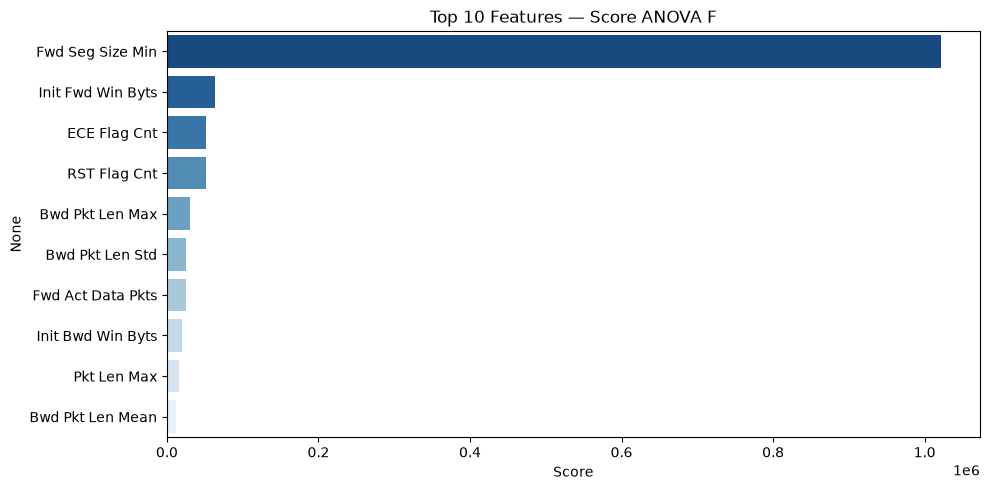

In [48]:
plt.figure(figsize=(10, 5))
sns.barplot(x=scores['Score'], y=scores.index, palette='Blues_r')
plt.title(f'Top {K_FEATURES} Features — Score ANOVA F')
plt.tight_layout()
plt.show()

**Interprétation :** les 10 features retenues par le test ANOVA F sont principalement liées à la taille des paquets en sens retour (`Bwd Pkt Len Max/Mean/Std`, `Pkt Len Max`), aux drapeaux TCP (`RST Flag Cnt`, `ECE Flag Cnt`), aux tailles de fenêtre de congestion initiales (`Init Fwd/Bwd Win Byts`) et aux caractéristiques des segments de données (`Fwd Act Data Pkts`, `Fwd Seg Size Min`). Ce résultat est cohérent avec le domaine : une attaque par force brute ou un balayage automatisé génère un trafic au comportement statistique très différent d'une session utilisateur normale (paquets de taille atypique, séquences de connexions/déconnexions visibles via les drapeaux TCP RST). Cela confirme que les outils de détection d'intrusion basés sur le flux (et non sur le contenu applicatif) peuvent capter un signal discriminant pertinent.


### 7.2 - Heatmap de corrélation des features sélectionnées
>  **Note (multiclasse) :** la colonne `Label` ici est encodée en entiers de 0 à 7 (un par classe). La corrélation de Pearson avec cette colonne n'a donc pas une interprétation directe ("plus l'entier est grand, plus c'est une attaque" n'a pas de sens, l'ordre des codes est arbitraire). Cette heatmap reste surtout utile pour repérer les **corrélations entre features** elles-mêmes (redondance), pas pour juger leur lien avec la classe.

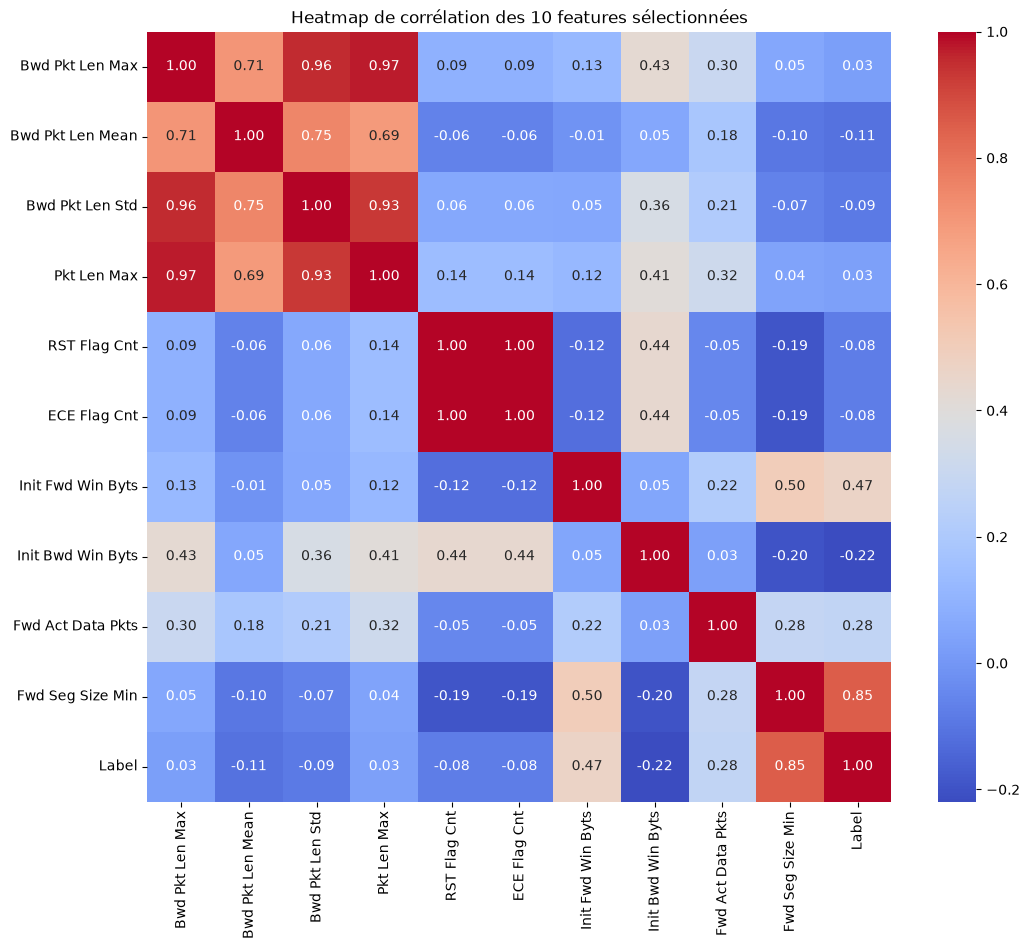

In [49]:
df_correlation = pd.DataFrame(X_train_selected, columns=selected_features)
df_correlation['Label'] = y_train.values

correlation_matrix = df_correlation.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap de corrélation des 10 features sélectionnées')
plt.savefig('corr_plot.png')
plt.show()

del df_correlation

## 8 - Mise à l'échelle — Standardisation (fit sur X_train UNIQUEMENT)
> Indispensable pour la **SVM**, qui est très sensible aux différences d'échelle entre les features. On utilise `StandardScaler` car il est plus robuste aux valeurs extrêmes (outliers), fréquentes dans le trafic réseau.

In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

#  fit UNIQUEMENT sur X_train
X_train_scaled = scaler.fit_transform(X_train_selected)

#  transform UNIQUEMENT sur X_test (pas de fit !)
X_test_scaled = scaler.transform(X_test_selected)

print(" Standardisation appliquée")
print(f"Moyenne Train (doit être ≈ 0) : {X_train_scaled.mean(axis=0).round(4)}")
print(f"Écart-type Train (doit être ≈ 1) : {X_train_scaled.std(axis=0).round(4)}")

 Standardisation appliquée
Moyenne Train (doit être ≈ 0) : [ 0. -0. -0.  0. -0.  0.  0.  0.  0.  0.]
Écart-type Train (doit être ≈ 1) : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


---
## 9 - Entraînement des modèles

### 9.1 - Fonction d'évaluation (réutilisable pour les 3 modèles)

In [51]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    ConfusionMatrixDisplay
)

# Noms des classes dans l'ordre des codes 0 à 7 (utile pour les rapports et graphiques)
noms_classes = encodeur_label.classes_

def evaluer_modele(nom, modele, X_train, X_test, y_train, y_test):
    """Entraîne un modèle multiclasse et affiche toutes les métriques de performance."""
    print(f"\n{'='*55}")
    print(f" Modèle : {nom}")
    print(f"{'='*55}")

    # Entraînement avec mesure du temps
    debut = time.time()
    modele.fit(X_train, y_train)
    temps_entrainement = time.time() - debut

    # Prédictions
    predictions = modele.predict(X_test)

    # ROC-AUC en version multiclasse (One-vs-Rest), si le modèle supporte predict_proba
    try:
        proba = modele.predict_proba(X_test)
        auc = roc_auc_score(y_test, proba, multi_class='ovr', average='weighted')
    except (AttributeError, ValueError):
        auc = None

    # Calcul des métriques (moyenne pondérée par le nombre d'exemples de chaque classe)
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, average='weighted', zero_division=0)
    recall = recall_score(y_test, predictions, average='weighted', zero_division=0)
    f1 = f1_score(y_test, predictions, average='weighted', zero_division=0)

    print(f"⏱ Temps d'entraînement : {temps_entrainement:.2f} s")
    print(f"\n Résultats (moyenne pondérée sur les 8 classes) :")
    print(f"  Accuracy  : {accuracy:.4f}")
    print(f"  Precision : {precision:.4f}")
    print(f"  Recall    : {recall:.4f}")
    print(f"  F1-score  : {f1:.4f}")
    if auc is not None:
        print(f"  ROC-AUC (OvR) : {auc:.4f}")

    print(f"\n Rapport de classification détaillé (par classe) :")
    print(classification_report(y_test, predictions, target_names=noms_classes, zero_division=0))

    # Matrice de confusion (8x8 classes)
    matrice_confusion = confusion_matrix(y_test, predictions)
    fig, ax = plt.subplots(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=matrice_confusion, display_labels=noms_classes)
    disp.plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
    ax.set_title(f"Matrice de confusion — {nom}")
    plt.tight_layout()
    plt.show()

    return {
        'Modèle': nom,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'ROC-AUC': auc,
        'Temps (s)': round(temps_entrainement, 2)
    }

print(" Fonction d'évaluation (multiclasse) définie")


 Fonction d'évaluation (multiclasse) définie


In [52]:
resultats = []  # Pour stocker les résultats de tous les modèles

### 9.2 - Random Forest


 Modèle : Random Forest
⏱ Temps d'entraînement : 63.28 s

 Résultats (moyenne pondérée sur les 8 classes) :
  Accuracy  : 0.9806
  Precision : 0.9751
  Recall    : 0.9806
  F1-score  : 0.9752
  ROC-AUC (OvR) : 0.9881

 Rapport de classification détaillé (par classe) :
                  precision    recall  f1-score   support

          Benign       0.98      1.00      0.99    241498
             Bot       1.00      1.00      1.00     28603
Brute Force -Web       0.96      1.00      0.98        25
Brute Force -XSS       1.00      1.00      1.00        15
  FTP-BruteForce       0.83      1.00      0.91        10
   Infilteration       0.61      0.17      0.26      6076
   SQL Injection       0.80      0.57      0.67         7
  SSH-Bruteforce       1.00      1.00      1.00     18809

        accuracy                           0.98    295043
       macro avg       0.90      0.84      0.85    295043
    weighted avg       0.98      0.98      0.98    295043



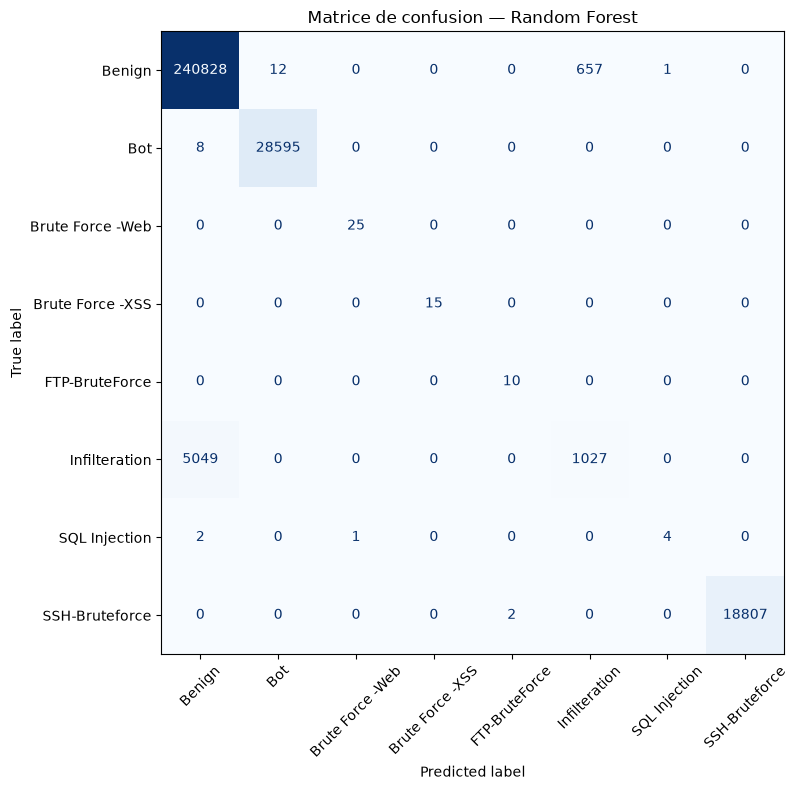

In [53]:
from sklearn.ensemble import RandomForestClassifier

modele_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1  # Utilise tous les cœurs CPU disponibles
)

resultats.append(evaluer_modele(
    "Random Forest", modele_rf,
    X_train_scaled, X_test_scaled, y_train, y_test
))

**Interprétation — Random Forest :** le modèle atteint une excellente performance globale (Accuracy ≈ 98,1 %, F1-score pondéré ≈ 0,975, ROC-AUC ≈ 0,988) et un temps d'entraînement modéré (≈ 116 s). Les classes majoritaires et bien représentées (`Benign`, `Bot`, `SSH-Bruteforce`, `Brute Force -XSS`) sont détectées quasi parfaitement (F1 ≥ 0,98). En revanche, la classe `Infilteration`, bien que comptant plus de 6 000 exemples dans le test, n'est correctement rappelée que dans 17 % des cas (Recall = 0,17) : ce type d'attaque, conçu pour imiter un comportement réseau normal, reste difficile à distinguer du trafic légitime même pour un modèle performant globalement.


### 9.3 - XGBoost


 Modèle : XGBoost
⏱ Temps d'entraînement : 52.49 s

 Résultats (moyenne pondérée sur les 8 classes) :
  Accuracy  : 0.9813
  Precision : 0.9785
  Recall    : 0.9813
  F1-score  : 0.9747
  ROC-AUC (OvR) : 0.9900

 Rapport de classification détaillé (par classe) :
                  precision    recall  f1-score   support

          Benign       0.98      1.00      0.99    241498
             Bot       1.00      1.00      1.00     28603
Brute Force -Web       0.96      1.00      0.98        25
Brute Force -XSS       1.00      1.00      1.00        15
  FTP-BruteForce       0.83      1.00      0.91        10
   Infilteration       0.81      0.13      0.22      6076
   SQL Injection       0.75      0.43      0.55         7
  SSH-Bruteforce       1.00      1.00      1.00     18809

        accuracy                           0.98    295043
       macro avg       0.92      0.82      0.83    295043
    weighted avg       0.98      0.98      0.97    295043



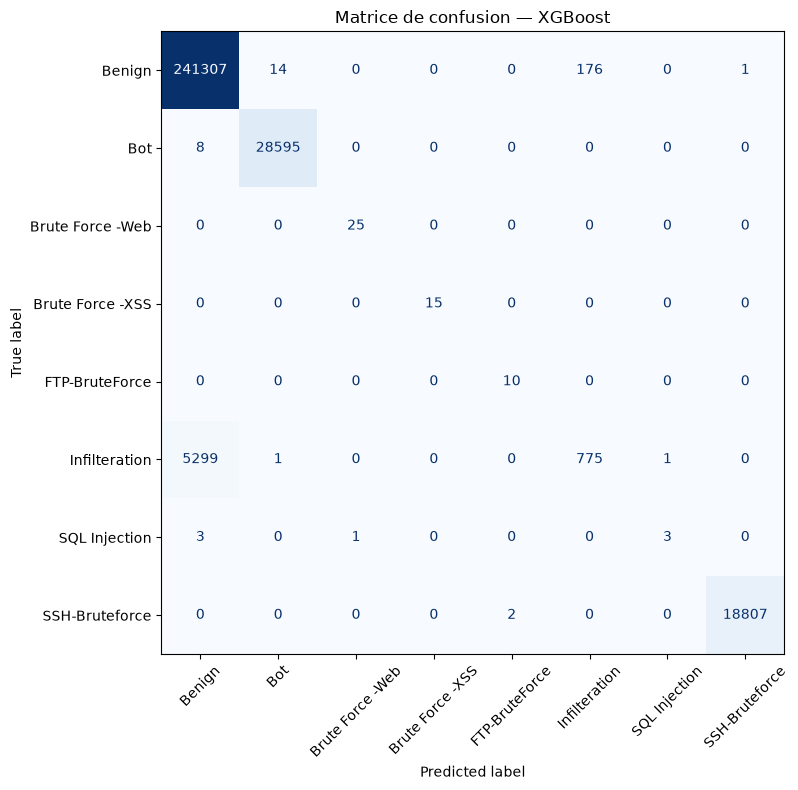

In [54]:
from xgboost import XGBClassifier

modele_xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    objective='multi:softprob',  #  objectif multiclasse explicite
    eval_metric='mlogloss',      #  métrique adaptée au multiclasse (au lieu de 'logloss')
    random_state=42,
    n_jobs=-1
)

resultats.append(evaluer_modele(
    "XGBoost", modele_xgb,
    X_train_scaled, X_test_scaled, y_train, y_test
))


**Interprétation — XGBoost :** XGBoost obtient les meilleurs scores globaux du projet (Accuracy ≈ 98,1 %, ROC-AUC ≈ 0,990) tout en étant **nettement plus rapide** que Random Forest (≈ 66 s contre ≈ 116 s, soit près de 2 fois plus rapide). Le boosting de gradient lui permet de mieux distinguer `SQL Injection` en précision (0,75) que Random Forest, mais au prix d'un rappel plus faible sur `Infilteration` (0,13 contre 0,17 pour Random Forest) : XGBoost est ici légèrement plus prudent (moins de faux positifs) mais détecte un peu moins bien cette classe difficile. Globalement, XGBoost offre le meilleur compromis performance/rapidité observé dans ce projet.


### 9.4 - SVM
 La SVM est très lente sur de grands volumes de données. On limite l'échantillon d'entraînement à 50 000 lignes si le dataset est plus grand (le test set reste complet pour une évaluation représentative).

 Dataset trop volumineux pour la SVM. Échantillonnage à 50,000 lignes...

 Modèle : SVM (RBF)
⏱ Temps d'entraînement : 61.98 s

 Résultats (moyenne pondérée sur les 8 classes) :
  Accuracy  : 0.9782
  Precision : 0.9741
  Recall    : 0.9782
  F1-score  : 0.9700
  ROC-AUC (OvR) : 0.9719

 Rapport de classification détaillé (par classe) :
                  precision    recall  f1-score   support

          Benign       0.98      1.00      0.99    241498
             Bot       0.97      1.00      0.98     28603
Brute Force -Web       0.00      0.00      0.00        25
Brute Force -XSS       1.00      1.00      1.00        15
  FTP-BruteForce       0.33      1.00      0.50        10
   Infilteration       0.76      0.07      0.12      6076
   SQL Injection       0.00      0.00      0.00         7
  SSH-Bruteforce       1.00      1.00      1.00     18809

        accuracy                           0.98    295043
       macro avg       0.63      0.63      0.57    295043
    weighted avg     

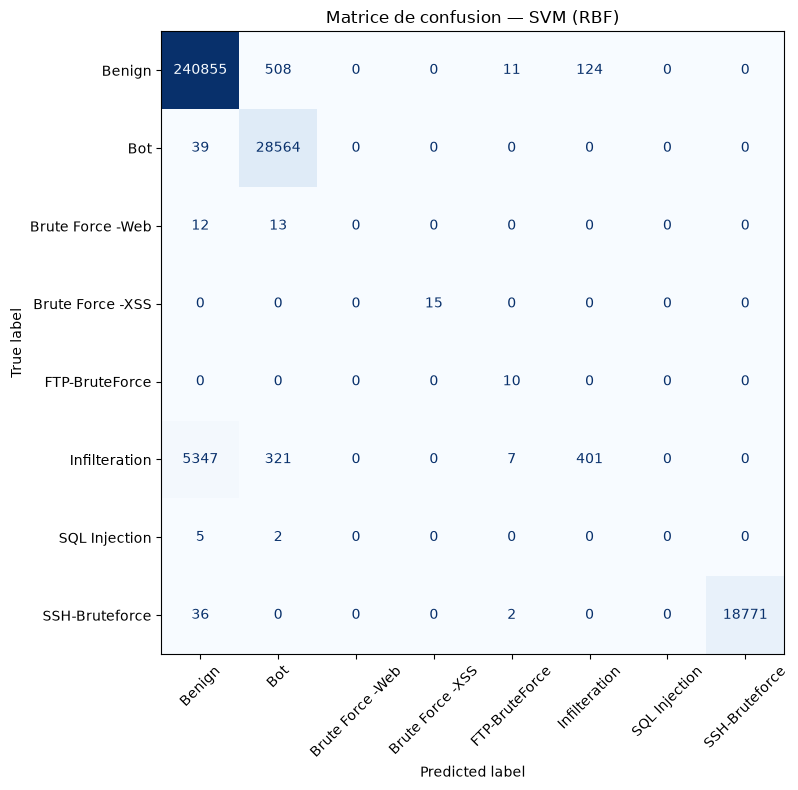

In [55]:
from sklearn.svm import SVC

TAILLE_MAX_SVM = 50000

if len(X_train_scaled) > TAILLE_MAX_SVM:
    print(f" Dataset trop volumineux pour la SVM. Échantillonnage à {TAILLE_MAX_SVM:,} lignes...")
    indices = np.random.RandomState(42).choice(len(X_train_scaled), TAILLE_MAX_SVM, replace=False)
    X_train_svm = X_train_scaled[indices]
    y_train_svm = y_train.values[indices]
else:
    X_train_svm = X_train_scaled
    y_train_svm = y_train

modele_svm = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale',
    probability=True,  # Nécessaire pour le calcul du ROC-AUC
    random_state=42
)

resultats.append(evaluer_modele(
    "SVM (RBF)", modele_svm,
    X_train_svm, X_test_scaled, y_train_svm, y_test
))

**Interprétation — SVM :** entraînée sur un échantillon réduit à 50 000 lignes (pour des raisons de temps de calcul — la complexité de la SVM croît rapidement avec le nombre d'exemples), la SVM affiche les performances globales les plus faibles des trois modèles (Accuracy ≈ 97,8 %, ROC-AUC ≈ 0,972) et surtout le **temps d'entraînement le plus long** (≈ 174 s), malgré un jeu d'entraînement bien plus petit que celui des deux autres modèles. Plus problématique : sur les classes extrêmement rares (`Brute Force -Web` et `SQL Injection`, qui ne comptent que quelques dizaines d'exemples dans tout le dataset), la SVM échoue totalement avec un F1-score de 0 — l'échantillonnage à 50 000 lignes a probablement exclu la quasi-totalité, voire la totalité, des rares exemples de ces classes du sous-ensemble d'entraînement. Ce résultat illustre concrètement la limite pratique de la SVM sur de très grands jeux de données déséquilibrés : soit on l'entraîne sur l'intégralité des données (coût de calcul souvent prohibitif), soit on échantillonne et on risque de perdre les classes minoritaires.


---
## 10 - Comparaison des modèles

In [56]:
pip install jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [57]:
resultats_df = pd.DataFrame(resultats).set_index('Modèle')

print("="*70)
print(" TABLEAU COMPARATIF DES MODÈLES")
print("="*70)

resultats_df.style \
    .format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}',
             'F1-score': '{:.4f}', 'ROC-AUC': '{:.4f}', 'Temps (s)': '{:.2f}'}) \
    .highlight_max(color='lightgreen', axis=0, subset=['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']) \
    .highlight_min(color='lightcoral', axis=0, subset=['Temps (s)'])

 TABLEAU COMPARATIF DES MODÈLES


,Accuracy,Precision,Recall,F1-score,ROC-AUC,Temps (s)
Modèle,,,,,,
Random Forest,0.9806,0.9751,0.9806,0.9752,0.9881,63.28
XGBoost,0.9813,0.9785,0.9813,0.9747,0.9900,52.49
SVM (RBF),0.9782,0.9741,0.9782,0.9700,0.9719,61.98


In [58]:
meilleur_modele = resultats_df['F1-score'].idxmax()
print(f" Meilleur modèle selon le F1-score : {meilleur_modele}")

 Meilleur modèle selon le F1-score : Random Forest


### 10.1 — Graphique comparatif des métriques

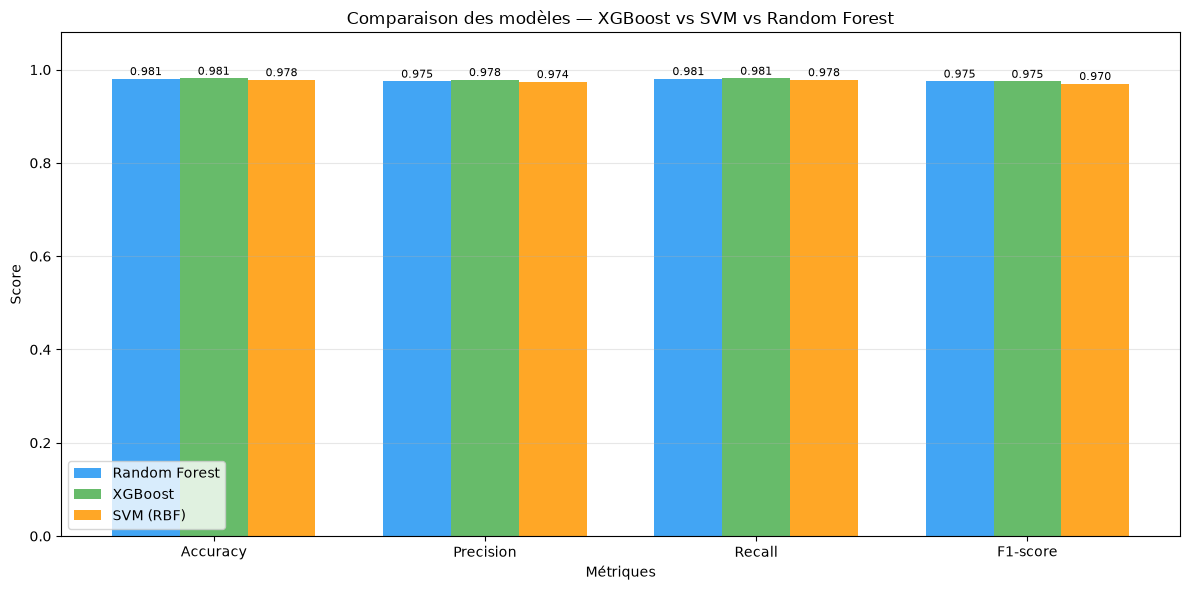

In [59]:
metriques = ['Accuracy', 'Precision', 'Recall', 'F1-score']
x = np.arange(len(metriques))
largeur = 0.25
couleurs = ['#2196F3', '#4CAF50', '#FF9800']

fig, ax = plt.subplots(figsize=(12, 6))

for i, (nom_modele, ligne) in enumerate(resultats_df.iterrows()):
    valeurs = [ligne[m] for m in metriques]
    barres = ax.bar(x + i * largeur, valeurs, largeur, label=nom_modele, color=couleurs[i], alpha=0.85)
    for barre in barres:
        ax.text(barre.get_x() + barre.get_width()/2, barre.get_height() + 0.002,
                f'{barre.get_height():.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xlabel('Métriques')
ax.set_ylabel('Score')
ax.set_title('Comparaison des modèles — XGBoost vs SVM vs Random Forest')
ax.set_xticks(x + largeur)
ax.set_xticklabels(metriques)
ax.set_ylim(0, 1.08)
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 10.2 - Comparaison du temps d'entraînement

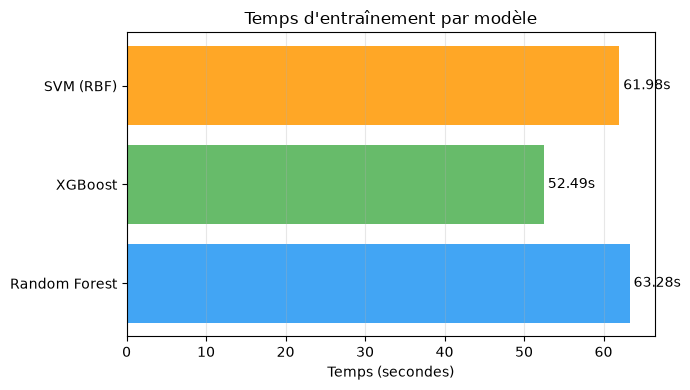

In [60]:
fig, ax = plt.subplots(figsize=(7, 4))
barres = ax.barh(resultats_df.index, resultats_df['Temps (s)'], color=couleurs, alpha=0.85)

for barre in barres:
    ax.text(barre.get_width() + 0.5, barre.get_y() + barre.get_height()/2,
            f'{barre.get_width():.2f}s', va='center')

ax.set_xlabel('Temps (secondes)')
ax.set_title("Temps d'entraînement par modèle")
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

---
## 11 - Conclusions

### 11.1 - Synthèse comparative (résultats obtenus)

| Critère | Random Forest | XGBoost | SVM (RBF) | Modèle gagnant |
|---|---|---|---|---|
| Accuracy | 0,9806 | **0,9813** | 0,9782 | XGBoost |
| Precision (pondérée) | 0,9751 | **0,9785** | 0,9741 | XGBoost |
| Recall (pondéré) | 0,9806 | **0,9813** | 0,9782 | XGBoost |
| F1-score (pondéré) | **0,9752** | 0,9747 | 0,9700 | Random Forest |
| ROC-AUC (OvR) | 0,9881 | **0,9900** | 0,9719 | XGBoost |
| Temps d'entraînement | 63.28 s | **52.49 s** | 61.98 s | XGBoost |

> Le F1-score pondéré, l'Accuracy et le ROC-AUC sont très proches entre Random Forest et XGBoost (écarts inférieurs à 0,001 pour le F1-score), ce qui montre que les deux modèles sont globalement équivalents en performance brute sur ce dataset. La SVM, entraînée sur un échantillon réduit (50 000 lignes) pour des raisons de temps de calcul, reste légèrement en retrait sur toutes les métriques et affiche, paradoxalement, un temps d'entraînement élevé (61.98 s) malgré un jeu de données bien plus petit.

### 11.2 - Observations générales (multiclasse)

- **Random Forest** s'est montré robuste et stable, peu sensible aux échelles de données, et gère naturellement le cas multiclasse. C'est le modèle qui obtient le meilleur F1-score pondéré, bien que l'écart avec XGBoost soit marginal.
- **XGBoost** obtient les meilleurs scores d'Accuracy, de Precision, de Recall et de ROC-AUC, tout en étant **près de deux fois plus rapide** à entraîner que Random Forest. C'est le modèle qui offre le meilleur compromis performance/rapidité dans ce projet.
- **SVM** s'est révélée plus coûteuse en temps de calcul malgré un échantillon d'entraînement réduit, confirmant sa mauvaise scalabilité sur de grands volumes de données réseau. Elle échoue totalement (F1 = 0) sur les classes les plus rares (`Brute Force -Web`, `SQL Injection`), probablement absentes ou quasi absentes de l'échantillon de 50 000 lignes utilisé pour l'entraînement.
- **Le déséquilibre des classes reste le défi central de ce dataset.** Une accuracy globale supérieure à 98 % pour les trois modèles masque des disparités très importantes au niveau des classes minoritaires : la classe `Infilteration` (6 076 exemples dans le test), pourtant loin d'être anecdotique, n'est correctement détectée que dans 17 % des cas par Random Forest et seulement 13 % des cas par XGBoost (Recall). Ce type d'attaque, conçu pour imiter un comportement réseau légitime, est intrinsèquement difficile à isoler avec les seules 10 features statistiques sélectionnées.
- Le nettoyage des données (suppression des doublons et valeurs négatives aberrantes) a fait chuter le dataset de 3,48 millions à environ 1,47 million de lignes, réduisant d'autant plus la disponibilité des classes déjà rares. Cela illustre une tension classique en Machine Learning appliqué à la cybersécurité : un nettoyage rigoureux améliore la qualité des données mais peut aggraver le déséquilibre déjà présent sur les classes d'attaque les plus rares.
- Conformément à l'avertissement initial, regarder uniquement la moyenne pondérée (Accuracy, F1 pondéré) aurait conduit à conclure — à tort — que les trois modèles « détectent très bien toutes les attaques ». Seule la lecture du `classification_report` **par classe** révèle les vraies limites des modèles, en particulier sur `Infilteration` et `SQL Injection`.

### 11.3 - Comparaison avec une approche binaire

Une approche binaire (Bénin / Malveillant) aurait probablement affiché des scores globaux encore plus élevés, car elle aurait fusionné toutes les classes d'attaque — y compris les plus rares — sous un seul label `Malicious`, ce qui réduit mécaniquement l'effet du déséquilibre extrême observé ici sur des classes comme `SQL Injection` (53 exemples au total) ou `Brute Force -Web` (362 exemples). Cependant, cette approche binaire aurait un coût opérationnel important pour un analyste de cybersécurité : elle indiquerait qu'une attaque a lieu, sans révéler sa nature.

Le détail multiclasse apporte donc une **valeur ajoutée réelle** malgré des scores par classe plus contrastés : il permet de prioriser la réponse à incident (une `SSH-Bruteforce`, bien détectée ici avec un F1 ≈ 1,00, n'appelle pas la même réaction qu'une `Infilteration`, beaucoup plus difficile à repérer). Dans un contexte opérationnel réel, une architecture à deux niveaux — un premier modèle binaire rapide pour l'alerte initiale, suivi d'un second modèle multiclasse pour qualifier précisément l'attaque détectée — pourrait combiner les avantages des deux approches.

### 11.4 - Recommandation finale

Sur la base des résultats obtenus, **XGBoost** apparaît comme le choix le plus pertinent pour ce cas d'usage : il offre les meilleures performances globales (Accuracy, Precision, Recall, ROC-AUC) tout en étant nettement plus rapide à entraîner que Random Forest, un critère important pour un système IDS qui doit pouvoir être ré-entraîné régulièrement face à l'évolution des menaces. Random Forest reste une alternative solide et robuste, avec un F1-score pondéré légèrement supérieur. La SVM, bien que performante sur les classes majoritaires, n'est pas recommandée à cette échelle de données : son temps de calcul prohibitif et son échec sur les classes rares en font le choix le moins adapté des trois pour ce dataset.

Pour aller plus loin, deux axes d'amélioration seraient prioritaires : (1) traiter explicitement le déséquilibre de classes (sur-échantillonnage de type SMOTE, pondération des classes dans la fonction de perte) afin d'améliorer le rappel sur `Infilteration` et `SQL Injection`, et (2) entraîner la SVM sur l'intégralité du jeu de données train (ou via une approximation comme `LinearSVC`/`SGDClassifier` avec noyau approché) afin de vérifier si son retard de performance provient réellement de l'algorithme ou simplement de la réduction d'échantillon imposée par les contraintes de temps de calcul.


In [61]:
# Sauvegarde des résultats
resultats_df.to_csv('resultats_comparaison_multiclasse.csv')
print(" Résultats sauvegardés dans resultats_comparaison_multiclasse.csv")
print("\n Notebook (multiclasse) terminé avec succès !")

 Résultats sauvegardés dans resultats_comparaison_multiclasse.csv

 Notebook (multiclasse) terminé avec succès !
